# EDA: tweet_eval sentiment

`splits` hold the texts after `clean_text`, which is what the model will see. `raw_splits` keep the texts exactly as in the CSV files; section 4 shows why the cleaning is needed.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.container import BarContainer

from itg_transformers.config import LABELS, SPLITS
from itg_transformers.data import load_split
from itg_transformers.eda import (
    TWITTER_PATTERNS,
    class_distribution,
    conflicting_rows,
    duplicates_summary,
    log_odds_z,
    matches,
    pattern_shares,
    sample_per_class,
    split_overlap,
    text_lengths,
    truncation_shares,
    word_counts,
)
from itg_transformers.metrics import classification_scores
from itg_transformers.tokenization import count_tokens, load_tokenizer

pd.set_option("display.max_colwidth", None)

raw_splits = {name: load_split(name, clean=False) for name in SPLITS}
splits = {name: load_split(name) for name in SPLITS}

## 1. Sanity check: duplicates and leakage

In [2]:
duplicates_summary(splits)

,rows,exact_duplicates,normalized_duplicates,conflicting_texts
train,45615,41,42,6
validation,2000,0,0,0
test,12284,2,4,2


Texts that occur several times in train with different labels. Each row is one occurrence: the index is the row number in `train.csv`, rows with the same text are placed next to each other.

In [3]:
conflicts = conflicting_rows(splits["train"])
conflicts.assign(label_name=conflicts["label"].map(LABELS))

,text,label,label_name
16929,An emotionally intelligent organisation through mindfulness? Find out how with @user in San Fran in Dec pls RT!,1,neutral
18334,An emotionally intelligent organisation through mindfulness? Find out how with @user in San Fran in Dec pls RT!,2,positive
16293,Buses to replace train services on Sunday as fans flock to the National Bowl to see Foo Fighters | oneMK,2,positive
43865,Buses to replace train services on Sunday as fans flock to the National Bowl to see Foo Fighters | oneMK,1,neutral
38293,"Iowa GOP poll results are here, in 3rd place Jeb Bush with 23%, in 2nd place Donald Trump with 34% and in 1st place is JOHN CENA",2,positive
41563,"Iowa GOP poll results are here, in 3rd place Jeb Bush with 23%, in 2nd place Donald Trump with 34% and in 1st place is JOHN CENA",1,neutral
24426,"MILAN, Aug 30 (Reuters) - After losing only three league games last season Juventus have now lost the first two of the new campaign as a",0,negative
41586,"MILAN, Aug 30 (Reuters) - After losing only three league games last season Juventus have now lost the first two of the new campaign as a",1,neutral
28331,Not making it to the main debate stage may not be such a bad thing for Carly Fiorina,1,neutral
45079,Not making it to the main debate stage may not be such a bad thing for Carly Fiorina,0,negative


Text overlap between splits:

In [4]:
pd.Series(
    {
        "train → validation": split_overlap(
            splits["train"], splits["validation"]
        ),
        "train → test": split_overlap(splits["train"], splits["test"]),
        "validation → test": split_overlap(
            splits["validation"], splits["test"]
        ),
    },
    name="overlapping_texts",
)

train → validation    3
train → test          0
validation → test     0
Name: overlapping_texts, dtype: int64

## 2. Class distribution

In [5]:
class_distribution(splits, LABELS)

label,negative,neutral,positive
train,7093,20673,17849
validation,312,869,819
test,3972,5937,2375


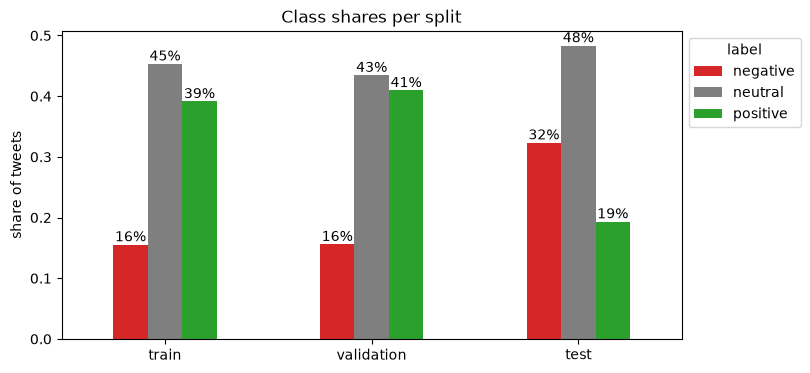

In [6]:
shares = class_distribution(splits, LABELS, normalize=True)
ax = shares.plot.bar(
    figsize=(8, 4), rot=0, color=["#d62728", "#7f7f7f", "#2ca02c"]
)
ax.legend(title="label", loc="upper left", bbox_to_anchor=(1, 1))
ax.set_ylabel("share of tweets")
ax.set_title("Class shares per split")
for bars in ax.containers:
    if isinstance(bars, BarContainer):
        ax.bar_label(bars, fmt="{:.0%}")
plt.show()

### Trivial baseline

Always predict the most frequent class of train. Any real model has to beat these numbers.

In [7]:
majority = int(splits["train"]["label"].mode().iloc[0])
print("Most frequent train class:", LABELS[majority])

pd.DataFrame(
    {
        name: classification_scores(
            splits[name]["label"].tolist(),
            [majority] * len(splits[name]),
        )
        for name in ("validation", "test")
    }
).T.round(3)

Most frequent train class: neutral


,accuracy,macro_f1
validation,0.434,0.202
test,0.483,0.217


## 3. Text length

Length in characters, whitespace-separated words and tokens of the `distilbert-base-uncased` tokenizer. Token counts include the special tokens `[CLS]` and `[SEP]`, because they also take up room in `max_length`.

In [8]:
tokenizer = load_tokenizer()
print("Model max length:", tokenizer.model_max_length)

lengths = pd.concat(
    [
        text_lengths(frame["text"]).assign(
            tokens=count_tokens(tokenizer, frame["text"].tolist()),
            label=frame["label"].map(LABELS),
            split=name,
        )
        for name, frame in splits.items()
    ],
    ignore_index=True,
)
lengths.groupby("split", sort=False)[["chars", "words", "tokens"]].median()

Model max length: 512


,chars,words,tokens
split,,,
train,111.0,20.0,29.0
validation,113.0,20.0,29.0
test,95.0,15.0,26.0


In [9]:
lengths.groupby("split", sort=False)["tokens"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
).round(1)

,count,mean,std,min,50%,90%,95%,99%,max
split,,,,,,,,,
train,45615.0,28.5,7.3,5.0,29.0,37.0,40.0,44.0,69.0
validation,2000.0,28.7,7.3,7.0,29.0,37.0,40.0,44.0,59.0
test,12284.0,25.4,8.4,3.0,26.0,36.0,39.0,45.0,75.0


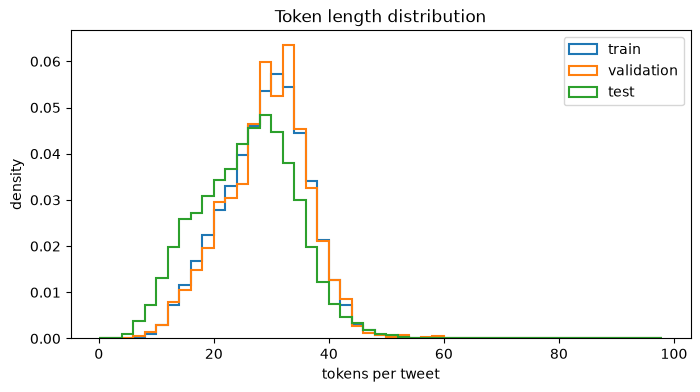

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in SPLITS:
    ax.hist(
        lengths.loc[lengths["split"] == name, "tokens"],
        bins=range(0, 100, 2),
        density=True,
        histtype="step",
        linewidth=1.5,
        label=name,
    )
ax.set_xlabel("tokens per tweet")
ax.set_ylabel("density")
ax.set_title("Token length distribution")
ax.legend()
plt.show()

### Length by class (train)

In [11]:
train_lengths = lengths[lengths["split"] == "train"]
train_lengths.groupby("label")[["chars", "words", "tokens"]].agg(
    ["mean", "median"]
).round(1).reindex(list(LABELS.values()))

chars        words        tokens       
           mean median  mean median   mean median
label                                            
negative  110.2  115.0  20.2   21.0   29.6   30.0
neutral   104.3  111.0  19.0   19.0   28.2   29.0
positive  104.4  110.0  19.1   19.0   28.4   29.0

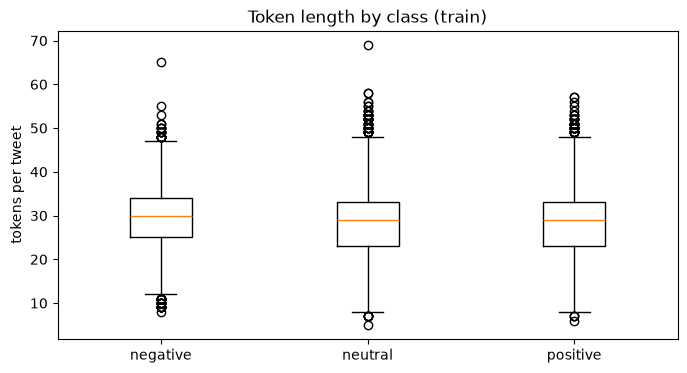

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(
    [
        train_lengths.loc[train_lengths["label"] == name, "tokens"]
        for name in LABELS.values()
    ],
    tick_labels=list(LABELS.values()),
)
ax.set_ylabel("tokens per tweet")
ax.set_title("Token length by class (train)")
plt.show()

### Choosing `max_length`

Share of tweets that would be truncated at each `max_length`.

In [13]:
pd.DataFrame(
    {
        name: truncation_shares(
            lengths.loc[lengths["split"] == name, "tokens"],
            [32, 48, 64, 128],
        )
        for name in SPLITS
    }
).map("{:.2%}".format)

,train,validation,test
32,30.65%,31.25%,19.85%
48,0.23%,0.35%,0.42%
64,0.00%,0.00%,0.01%
128,0.00%,0.00%,0.00%


## 4. Twitter-specific features

Share of tweets that contain each pattern, before and after `clean_text`. `caps_word` also counts acronyms like `NHL`, so it overestimates shouting.

In [14]:
pd.concat(
    {
        "raw": pattern_shares(raw_splits, TWITTER_PATTERNS),
        "clean": pattern_shares(splits, TWITTER_PATTERNS),
    },
    axis=1,
).map("{:.1%}".format)

raw                    clean                  
                train validation   test  train validation   test
user_mention    28.8%      30.5%  39.5%  28.8%      30.5%  39.5%
url              0.2%       0.1%   1.4%   0.2%       0.1%   1.4%
hashtag         18.7%      17.6%  39.3%  18.6%      17.6%  39.3%
emoticon         2.6%       2.1%   0.4%   2.8%       2.2%   0.4%
emoji            0.0%       0.0%   6.5%   0.0%       0.0%   6.5%
html_entity      4.2%       4.4%   0.1%   0.0%       0.0%   0.0%
unicode_escape  11.2%      10.3%   0.0%   0.0%       0.0%   0.0%
non_ascii        0.0%       0.0%  21.2%   7.1%       6.5%  21.2%
caps_word       22.1%      21.6%  20.2%  22.2%      21.6%  20.2%
elongated_word   1.9%       1.4%   1.0%   1.9%       1.4%   1.0%
repeated_punct   5.7%       5.7%   2.8%   5.7%       5.7%   2.8%
quote_wrapped   13.9%      13.0%   0.2%   0.0%       0.1%   0.0%

Two random raw examples per pattern from train and test:

In [15]:
examples = []
for name in ("train", "test"):
    texts = raw_splits[name]["text"]
    for key, pattern in TWITTER_PATTERNS.items():
        found = texts[matches(texts, pattern)]
        for text in found.sample(min(2, len(found)), random_state=0):
            examples.append({"split": name, "pattern": key, "text": text})
pd.DataFrame(examples).set_index(["split", "pattern"])

text
split pattern                                                                                                                                                         
train user_mention                                               Playing @user all day to prep for tomorrow\u2019s concert at Fort Canning. Go\u002c baby\u002c go go!
      user_mention               "Talking books with my 5th grade niece at our family Christmas She's a dystopian fantasy, Twilight girl. Must have learned from @user
      url                                                           "http://t.co/Q7Q8bJrT  who knows? may be one day, Eastern Province become an independent state !!"
      url                      News Alarm: Tim Byrdak (P - NYM) Tim Byrdak is going in for surgery with Dr. David Altchek in New York tomorrow. (http://t.co/GMrPWv9W)
      hashtag                                           ive been to the library twice and both times ive sat in swanky chairs watching netflix #lit #collegegoals #woo
      hashtag             One of the classic rivalries from the EPL era is renewed on Sunday when MANCHESTER UTD and Newcastle Utd meet at St James Park! #mufc #glory
      emoticon             @user I\u2019ll see you tomorrow! I\u2019ll be with my friend from Germany who came for her first hockey game! :) shed like to meet you! :)
      emoticon                                                                               @user dude!! Im going to a polish festival on sunday with my room mate :D
      html_entity           @user Happy Friday yall.....can u play ""feel it boy"" by Janet Jackson ft Beenie man &amp; then nthin (compares to you) by the Jacksons."
      html_entity                               From tonight's CCTV 7pm news report it sounds like Erdogan may have gotten a bit of a lecture from Xi &amp; pals today
      unicode_escape                                              I love Texas A&M\u002c but any team that drafts Tannehill before the 7th round has lost their minds.
      unicode_escape                                                                 All the people seeing Noel Fielding tomorrow\u002c I am extremely jealous of you.
      caps_word             "Persons who are favoring Yakub Menen, may be HAPPY on Gurdaspur Attack. Those persons should also be hanged till death along with Yakub."
      caps_word                                                                                The Daily Zap: Catch highlights from Thursday\u2019s action in the NBA.
      elongated_word   STONE COLD STEVE AUSTIN &amp; Wooooo RIC FLAIR is sat next to #WWESuperman RIGHT NOW here in the hotel bar. #FlyingHigh. #WWE #Summerslam week!
      elongated_word                                                          Ohhhhh the things I'd do for Dunkin donuts tomorrow morning.. @user is there one near us
      repeated_punct                                                                                real madrid sign a 7year old from argentina maybe the next messi!!
      repeated_punct                                    Team Kumite in Tohoku championship We got 3rd place!!This photo was taken 3years ago...Do you know which I am?
      quote_wrapped   "Since Midnight Memories, I knew that Zayn will be the 1st to left, I watched almost all of their performance &amp; Zayn is not that into them."
      quote_wrapped            "#SmartNCAA: It's another 'Yes para sa tres' for the ""Ant-man"" Mark Cruz! Letran still on top, 72-53 with 1:53 remaining in the 4th!"
test  user_mention                                                                                                           @user  are they all from @user  Who cares
      user_mention                                         @user I was referring to Steve Bannon and Sessions.  I'm sorry you're still so attached to a dead movement.
      url                  Giving Thanks for Foster Campbell,  We need 1 more Dem in the Senate to save Soc Sec,   Medicare & Medicaid .https://t.co/34UIL

### Escaped unicode in train and validation

Train and validation contain no real non-ASCII characters. Instead they store the literal escape sequences `\u002c` and `\u2019`, while test contains the real characters and emoji. Which escape codes occur and what they stand for:

In [16]:
escapes = (
    pd.concat([raw_splits["train"]["text"], raw_splits["validation"]["text"]])
    .str.extractall(r"(\\u[0-9a-fA-F]{4})")[0]
    .value_counts()
    .rename_axis("escape")
)
escapes.to_frame("count").assign(
    character=[chr(int(code[2:], 16)) for code in escapes.index]
)

,count,character
escape,,
\u002c,4843,","
\u2019,4589,’


How the tokenizer sees the same word written three ways:

In [17]:
for text in ["I can\\u2019t", "I can’t", "I can't"]:
    print(f"{text!r:18} -> {tokenizer.tokenize(text)}")

'I can\\u2019t'    -> ['i', 'can', '\\', 'u2', '##01', '##9', '##t']
'I can’t'          -> ['i', 'can', '’', 't']
"I can't"          -> ['i', 'can', "'", 't']


### Cleaning

`clean_text` decodes the escape codes and HTML entities, removes the quotes the export wrapped around tweets and collapses escaped inner quotes. Random train tweets changed by it:

In [18]:
raw_train = raw_splits["train"]["text"]
clean_train = splits["train"]["text"]
changed = raw_train != clean_train
print(f"Changed tweets: {changed.mean():.1%} of train")
pd.DataFrame({"raw": raw_train, "clean": clean_train})[changed].sample(
    8, random_state=0
)

Changed tweets: 29.3% of train


,raw,clean
36556,"""One for your diary. We have reindeer's coming to the garden centre on Saturday the 8th of December,""","One for your diary. We have reindeer's coming to the garden centre on Saturday the 8th of December,"
18446,"""George Osborne on British contributions """"we do not have a veto ... and we have to live with the consequences.""""","George Osborne on British contributions ""we do not have a veto ... and we have to live with the consequences."""
14945,"""Advertising is getting so aggressive, just saw a billboard asking """"""""will you get HIV today? will you get HIV tonight? How about tomorrow?""""""""""","Advertising is getting so aggressive, just saw a billboard asking ""will you get HIV today? will you get HIV tonight? How about tomorrow?"""
13903,"""out Castle sun. and staying there until Tues. Mother said \""""""""It aint safe up dere in that New York wit Sandy all thru dere\"""""""" Fvck you\u002c Sandy.""","out Castle sun. and staying there until Tues. Mother said ""It aint safe up dere in that New York wit Sandy all thru dere"" Fvck you, Sandy."
8526,I\u2019ll pretend like today is Friday and party it up like it\u2019s the end of a long week day. YOLO\u002c people\u002c YOLO. #headingtohipstertown!,"I’ll pretend like today is Friday and party it up like it’s the end of a long week day. YOLO, people, YOLO. #headingtohipstertown!"
19558,If Plant City didn\u2019t have a staples i don\u2019t know what i would do with my Friday nights.,If Plant City didn’t have a staples i don’t know what i would do with my Friday nights.
17497,"""if anyone brings me Dunkin iced coffee tomorrow, you'd be my hero""","if anyone brings me Dunkin iced coffee tomorrow, you'd be my hero"
31006,"""Been watching/reading Naruto since 6th grade, just finished the entire thing last night, man smh""","Been watching/reading Naruto since 6th grade, just finished the entire thing last night, man smh"


## 5. Vocabulary by class (train)

Words are lowercased, English stop words and `@user` are dropped, hashtags are kept as separate tokens like `#day`. Contractions such as `don't` are kept because negation matters for sentiment.

In [19]:
train = splits["train"]
class_counts = {
    name: word_counts(train.loc[train["label"] == label, "text"])
    for label, name in LABELS.items()
}
pd.DataFrame(
    {name: counts.index[:15] for name, counts in class_counts.items()}
).rename_axis("rank")

,negative,neutral,positive
rank,,,
0,tomorrow,tomorrow,tomorrow
1,just,just,day
2,like,going,just
3,1st,day,night
4,day,night,going
5,going,friday,friday
6,i'm,sunday,good
7,time,1st,i'm
8,don't,time,sunday


The most frequent words are the same for every class, so they say nothing about sentiment. Distinctive words are ranked by the z-score of the log-odds ratio of a class against the other two classes (`log_odds_z`). A high score means the word is much more typical for this class, taking into account how often it occurs overall.

In [20]:
distinctive = {
    name: log_odds_z(
        counts,
        word_counts(train.loc[train["label"] != label, "text"]),
    )
    for (label, name), counts in zip(
        LABELS.items(), class_counts.values(), strict=True
    )
}
pd.DataFrame(
    {name: z.index[:20] for name, z in distinctive.items()}
).rename_axis("rank")

,negative,neutral,positive
rank,,,
0,fuck,sox,happy
1,shit,gucci,love
2,worst,madrid,good
3,muslims,white,great
4,hate,kasich,best
5,sad,oliseh,excited
6,fucking,2012,day
7,stupid,john,birthday
8,don't,eagles,wait


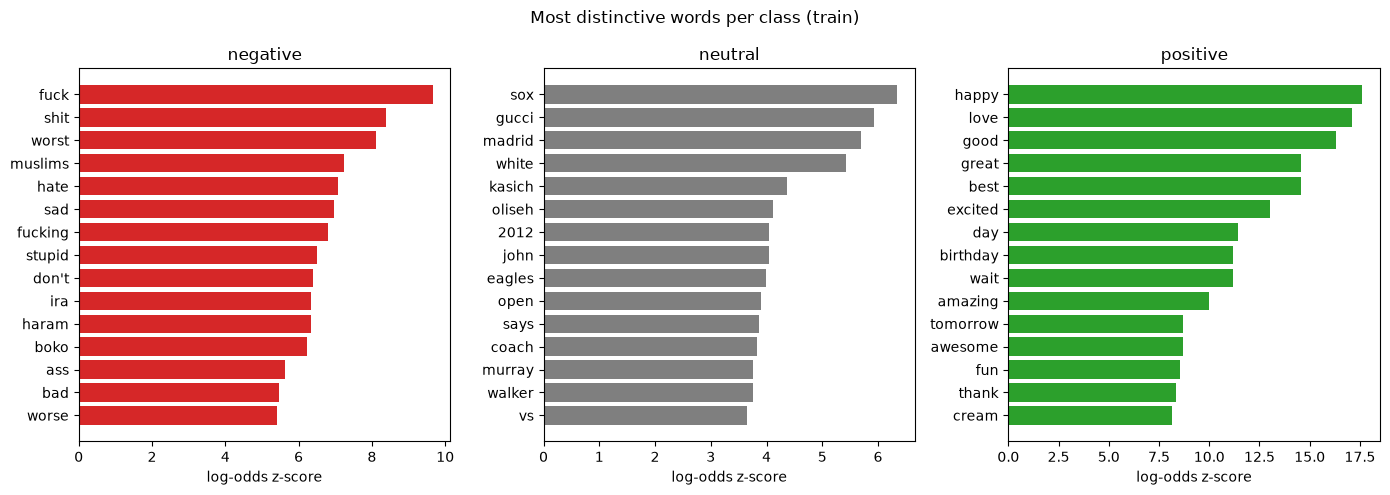

In [21]:
colors = {"negative": "#d62728", "neutral": "#7f7f7f", "positive": "#2ca02c"}
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (name, z) in zip(axes, distinctive.items(), strict=True):
    top = z.head(15)[::-1]
    ax.barh(top.index, top.to_numpy(), color=colors[name])
    ax.set_title(name)
    ax.set_xlabel("log-odds z-score")
fig.suptitle("Most distinctive words per class (train)")
fig.tight_layout()
plt.show()

### Train vs test vocabulary

The same score, but comparing the test split against train. It shows which topics appear only in one of them.

In [22]:
train_vs_test = log_odds_z(
    word_counts(splits["test"]["text"]), word_counts(train["text"])
)
pd.DataFrame(
    {
        "typical for test": train_vs_test.index[:20],
        "typical for train": train_vs_test.index[::-1][:20],
    }
).rename_axis("rank")

,typical for test,typical for train
rank,,
0,trump,tomorrow
1,voter,night
2,bannon,sunday
3,melania,1st
4,foundation,day
5,https,saturday
6,#isis,friday
7,liberals,2nd
8,alt,going


## 6. Reading examples

Ten random tweets of every class. The point is to judge by eye how noisy the labels are, numbers alone do not show that.

In [23]:
sample_per_class(splits["train"], LABELS, n=10)

text
label    row                                                                                                                                                
negative 4939       #CNET - Just bought my 1st iPad, iPad3, feeling real burned, mad, about iPad4 so soon. Grrr. REALLY mad! Don't even care about mini now,
         15545                                         Mother's Day is coming like tomorrow or is it today? idk, but i didn't prepare anything for me's mom.
         10440  Can't believe I left my charger at Tia's. I have just under 50% until tomorrow, so in living on my IPod. You can only contact me via Twitter
         13852                           If I didn't yell at someone about Taylor Swift or Kesha then the entire day was a waste. Try to be better tomorrow.
         9042                                    @user @user Nice Try - but why do you #LIE! (#Obama lies2) "Planned Parenthood does not provide mammograms"
         10259                                Oh shit Nicki and Mikey gone be in the same room tomorrow I wonder if Mikey gone talk all that shit then #VMAs
         15571                            Why does everything have to be compared with Muslims. At just 13% more non-Muslims eat meat than Muslims in India.
         20961                   @user done and done! I haven't seen the last few episodes. I don't have Internet until Monday so I can't download them yet.
         28946            @user Deeply inspired by David Bowie - ashes to ashes and pink floyd, set the controls for the heart of the sun = depressing game"
         10505                           Ahhhh the next few weekends are going to be messy! First off - this saturday: Powder Room at the Gladstone Hotel...
neutral  28661                                                    @user @user @user  I think this is the motive of the Yakub's laywers for pursuing the case
         8862                                @user From this performance it is obvious why David Miliband comes up 1st when you google Miliband! #onetowatch
         33658                                              @user @user We are actually playing on Saturday, January 19 - the week prior to the Senior Bowl.
         18564                                                                                   David Wright and his best friend both ground out in the 9th
         22243                     Gonna watch Seinfeld, smoke a joint, and pass the hell out before going back to work at 2 jobs again tomorrow. #adultshit
         20856                                                                           John kasich you may live. You dont have my support but you may live
         11585       @user @user I think not working closely with @user will hurt the brand, the beta has people buying & intending on buying PS4's for Nov"
         43126                                       he Charlie Hebdo shooting from January and the situation right now are 2 separate events. get it right.
         40954            FACT: The core of Carly Fiorina's support comes from people who knew nothing about her before 4:59 PM on Thursday. #CheckHerRecord
         31209                                   This day (26 Feb) in 1988 George Harrison received the award for "Video Of The Year" for "When We Was Fab".
positive 31177                           Kanye West was honored in a big way during Sunday night's MTV Video Music Awards by receiving the Michael Jackso...
         23609                                 Have you heard about Amazon Prime day? Don't miss it - July 15th! Yay! #ad #PrepForPrime @user #HappyPrimeDay
         3227                          Houston peeps: Go see Rumours (Fleetwood Mac cover band from Los Angeles) at @user on Saturday.  You won't regret it.
         7700                                                         I went to a Remembrance service today for the 1st time and can say it was so touching.
         5344                   Thanks to Moomba, I've been cruising w

In [24]:
sample_per_class(splits["test"], LABELS, n=10)

text
label    row                                                                                                                                               
negative 8726     @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? ARE THE THUGS  AND KIDS RUNNING OUR COUNTRY?
         3351         #BreakingNewslist of the terrorist groups at #Jordan meeting are..#Hamas #katabThawratAlAshreen #AlJaishAlislami #BaathParty & others
         7291                                                                             Racists masochists fascist all the hate words we deplorables are.
         3317                       @user @user @user Liberals probly Favored this Job Killin Bullshit Cluster fuck!TPP Would Slaughter Middle Class Income
         8816                @user spends $Millions on politicians like #Giuliani, to push #iran war, makes Kim Jong Un look humble!https://t.co/sQpap31XUj
         7233       @user Get lost you crooks. Your plan to bring #Burundi where you brought #Libya #Rwanda94 was defeated. Find your next victim elsewhere
         8804                                                                     The Socialist/Fascist Party (aka. Dems) is driving itself into obscurity.
         8398    They steal fox cubs off their moms to teach hounds to rip them apart for their sadism (Terrier-work). How else? It's sadistic! #KeepTheBan
         10258  yesterday was #NationalFastFoodDay, a day where one celebrates, praises, and eventually eats unhealthy food, this is a new low for humanity
         4530                   @user Kim Jong Un wishes his propaganda was a good as this.  BHO never uses the restroom either, We believe that. Wink wink
neutral  3774                              FINAL- Fairmont 38 Tippecanoe 28. Allison Mader 18 for Tipp, Madeine Westbeld 16 for Fairmont. #DaytonGirlsHoops
         8197                 Follow my buddy @user Want on my list of friend promos tweet me (Interactive Followers Only)#PJNET #Tcot #Tlot #TPP #TeaParty
         9345                                                    #AllStar 2011 Panini Gold Standard Stars Memorabilia 19 #LaMarcusAldridge Basketball #Card
         2825                                                                   UN Security Council to vote Monday on proposed ceasefire in Syria's Aleppo.
         3394                                                                                         Not for the #TrumpTransitionTeam it's a prerequisite.
         8614                            This woman is still talking about Melania Trump's admittedly plagiarized speech, guys.As in, she's still saying i…
         1085                                 Watching Scream Queens Season 2 Episode 5 'Chanel Pour Homme-icide' #ScreamQueens #ChanelPourHommeIcide @user
         2672                                                                                      #Google Earth now available in VR #HTC #virtualreality …
         9874                                                                                        11/16/16 FastCast: Cy Young winners revealed via @user
         8723                                        #MuhammadAli Muhammad Ali Leon Spinks On Site Boxing Press Brochure September 15 . 1978 #Legend #Boxer
positive 10724                                         United Nations Development Program (UNDP): South Korea offers USD 1M to support stability in #Libya.
         9305                  #Eurozone BREAKING: Vladimir Putin admits Kim Jong-un is better in every way and would "love to see... [his] face" #SydMUN16
         454                                                                                                                      @user Happy Thanksgiving!
         11849                                                                                              I think I have spent quite enough on Persona 5.
         248                                                                                New

### Observations

Roughly 2-4 of every 10 labels are debatable:

- **Neutral hides mild opinions.** Train 22243 ("pass the hell out before going back to work at 2 jobs"), 43126 ("get it right") and the sarcastic 40954 about Carly Fiorina read as negative.
- **News and ads are often labeled positive.** Train 16957 (Galaxy Note 5 event), test 10724 (UNDP offers USD 1M), 248 (new photo) and 8930 (an earrings listing) state facts without any sentiment.
- **Sarcasm.** Test 9305 (Putin "admits" Kim Jong-un is better) and 11849 ("I have spent quite enough on Persona 5") are labeled positive, the literal words win over the meaning.
- **Topic instead of tone.** Test 3351 is a plain list of groups at a meeting, labeled negative because it is about terrorism.
- **Mild annoyance counts as negative.** Train 20961 (no Internet until Monday) and 15545 (forgot Mother's Day) are barely emotional.

Most debatable cases involve the neutral class, which matches the conflicting duplicates from section 1.

## Summary

1. **No leakage worth worrying about.** After cleaning, 3 validation tweets also occur in train with the same label; test does not overlap with train.
2. **Classes are imbalanced and shifted.** Train is 16% negative, 45% neutral, 39% positive; test is 32% / 48% / 19%. Always predicting neutral gives 0.48 accuracy but only 0.22 macro-F1 on test, so **macro-F1 is the main metric**.
3. **`max_length = 64`** truncates less than 0.01% of tweets in every split. The model itself accepts up to 512 tokens.
4. **Train and validation needed cleaning** (`clean_text`): escaped `\u2019` and `\u002c`, HTML entities and export quotes. Emoji exist only in test and cannot be restored; the uncased DistilBERT vocabulary has no emoji, so 6.8% of test tweets contain `[UNK]`.
5. **Neutral has no vocabulary of its own** and is the source of most label noise. Expect most errors on neutral vs. positive/negative.
6. **Topics leak into labels.** Words like `muslims`, `ira`, `hebdo` are distinctive for negative. The model may learn topic shortcuts, worth checking on day 7.
7. **Test is about different things.** Train is about dates and events of 2012-2015, test about US politics of 2016-2017. Test metrics will be noticeably lower than validation metrics.